In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
len(words)

32033

In [5]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [88]:
# build the dataset

block_size = 3 #context length: how many characters do we take to predict the next one?
X, y = [], []
for w in words:
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        y.append(ix)
        context = context[1:] + [ix] #crop and append

X = torch.tensor(X)
y = torch.tensor(y)

In [89]:
X.shape, y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [10]:
C = torch.randn((27, 2))

In [23]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [24]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [57]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)

In [58]:
h

tensor([[ 0.9603,  0.0559, -0.9709,  ...,  0.0731, -0.4801, -0.0181],
        [ 0.5008, -0.1780, -0.9061,  ...,  0.6293, -0.0298, -0.9074],
        [ 0.9263,  0.4640, -0.6611,  ...,  0.6619,  0.4357, -0.3487],
        ...,
        [ 0.9993, -0.9123, -0.9747,  ..., -0.9770, -0.6740, -1.0000],
        [ 0.9857,  0.8520,  0.9915,  ..., -0.9383, -0.2392, -0.7583],
        [-0.8557, -0.7780, -0.9949,  ...,  0.9846,  0.9205, -0.9997]])

In [59]:
h.shape

torch.Size([32, 100])

In [60]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [61]:
logits = h @ W2 + b2

In [62]:
logits.shape

torch.Size([32, 27])

In [64]:
counts = logits.exp()

In [65]:
prob = counts / counts.sum(1, keepdim=True)

In [66]:
prob.shape

torch.Size([32, 27])

In [73]:
loss = -prob[torch.arange(32), y].log().mean()
loss

tensor(21.0346)

In [74]:
# rewrite a bit

In [90]:
X.shape, y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [142]:
g = torch.Generator().manual_seed(42)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [143]:
sum(p.nelement() for p in parameters)

3481

In [144]:
for p in parameters:
    p.requires_grad = True

In [145]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [156]:
lri = []
lossi = []
for i in range(100000):

    #minibatch construct
    ix = torch.randint(0, X.shape[0], (32, ))

    # forward pass
    emb = C[X[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y[ix])
    #print(loss.item())
    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    #update
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

    #track stats
    # lri.append(lr)
    # lossi.append(loss.item())


print(loss.item())

2.037656784057617


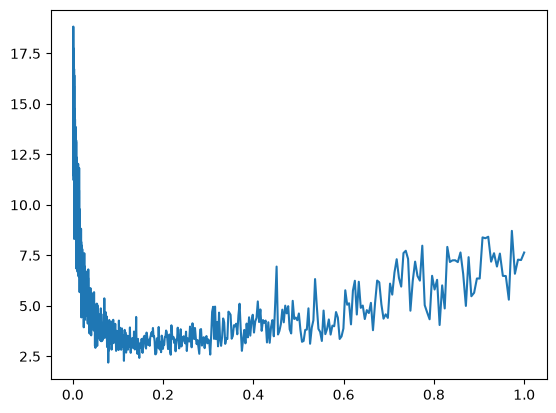

In [141]:
plt.plot(lri, lossi)

In [157]:
emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, y)
loss

tensor(2.1927, grad_fn=<NllLossBackward0>)

In [158]:
#training split, dev/validation split, test split
# 80%, 10%, 10%

In [159]:
def build_dataset(words):
    block_size = 3
    X, y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            y.append(ix)
            context = context[1:] + [ix] 

    X = torch.tensor(X)
    y = torch.tensor(y)

    print(X.shape)
    print(y.shape)
    return X, y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3])
torch.Size([182625])
torch.Size([22655, 3])
torch.Size([22655])
torch.Size([22866, 3])
torch.Size([22866])


In [190]:
g = torch.Generator().manual_seed(42)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

In [201]:

for i in range(100000):

    #minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32, ))

    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, ytr[ix])
    #print(loss.item())
    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    #update
    lr = 0.002
    for p in parameters:
        p.data += -lr * p.grad

In [202]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, ytr)
loss

tensor(2.0987, grad_fn=<NllLossBackward0>)

In [203]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1404, grad_fn=<NllLossBackward0>)

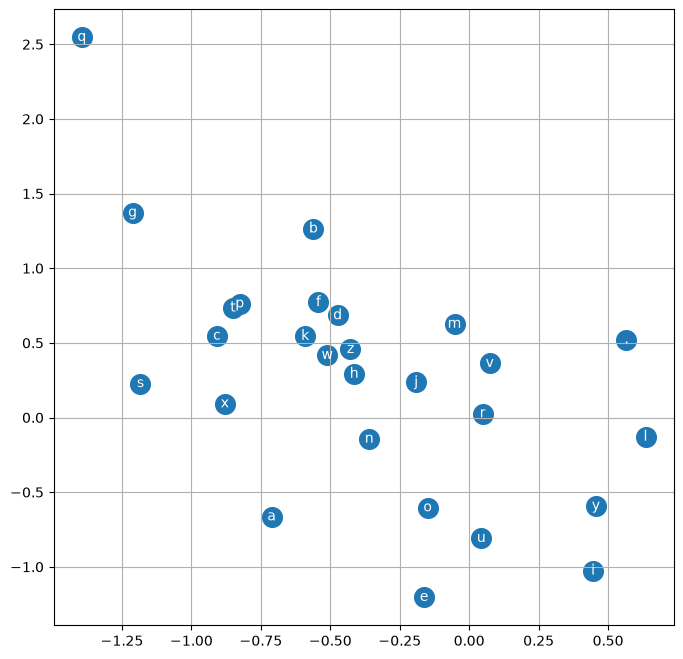

In [189]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")
plt.grid('minor')

In [204]:
for _ in range(20):

    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))

jacksony.
nita.
sani.
maketissarayden.
jamarcean.
lode.
myli.
khrishis.
skiry.
plar.
eraming.
kemek.
leigh.
braisebil.
isa.
karmilanie.
minsleya.
legwind.
kelle.
traysen.
